# 11 – Final Out-of-Sample Test

This notebook evaluates the forecasting performance of the selected model on the previously unseen 2026 test dataset.

Based on the 2025 validation results, OLS with a three-year rolling training window was selected as the preferred forecasting model.

The final evaluation covers January to October 2026 and follows the established forecasting protocol, including monthly model refitting and a five-day information lag.

Model performance is assessed using MAE and RMSE and compared with the Lag-7 baseline. The test data are used exclusively for final evaluation, without further model selection or tuning.

## 1. Load Test Data

The processed feature dataset is loaded, and observations belonging to the 2026 test period are identified.

The test period contains 304 daily observations from 1 January to 31 October 2026.



In [3]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define project directory
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()

# Load frozen feature dataset
features = pd.read_csv(
    ROOT / "data" / "processed" / "features.csv",
    parse_dates=["date"]
)

# Separate the final test period
test_data = features[
    features["period"] == "test"
].copy()

print("Feature dataset loaded successfully.")
print("Total observations:", len(features))
print("Test observations:", len(test_data))
print("Test start:", test_data["date"].min().date())
print("Test end:", test_data["date"].max().date())


Feature dataset loaded successfully.
Total observations: 3226
Test observations: 304
Test start: 2026-01-01
Test end: 2026-10-31



## 2. Model Features and Predictors

The selected OLS model uses 16 predictor variables, including historical electricity consumption, weather forecasts, calendar information, and holiday indicators.

Consumption lags capture recent demand patterns, while weather-related variables account for temperature-dependent electricity consumption. Calendar and holiday features help explain systematic differences between weekdays, weekends, and special periods.

The same feature set as in the 2025 validation is retained to ensure consistency between model selection and final testing.


In [4]:

# Feature configuration from Notebook 08

TARGET = "consumption_mwh"

LAG_FEATURES = [
    "lag_5",
    "lag_6",
    "lag_7",
    "lag_14",
    "lag_21",
    "lag_28",
    "lag_mean_5_11",
]

WEATHER_FEATURES = [
    "heating_degrees",
    "cooling_degrees",
    "forecast_precipitation",
]

CATEGORICAL_FEATURES = [
    "weekday",
    "month",
]

BINARY_FEATURES = [
    "is_holiday",
    "is_christmas_period",
    "lag_7_is_holiday",
    "lag_14_is_holiday",
]

NUMERIC_FEATURES = LAG_FEATURES + WEATHER_FEATURES

FEATURES = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
    + BINARY_FEATURES
)

# Check that all required features exist
assert len(FEATURES) == 16
assert all(col in features.columns for col in FEATURES)

print("Model configuration loaded successfully.")
print("Number of predictors:", len(FEATURES))
print("All required features are available.")


Model configuration loaded successfully.
Number of predictors: 16
All required features are available.



## 3. Model Pipeline and Preprocessing

The selected forecasting model is implemented using an Ordinary Least Squares (OLS) linear regression pipeline, consistent with the 2025 validation setup.

Numerical features are standardized using StandardScaler, while missing numerical values are handled through median imputation. Categorical variables are transformed using one-hot encoding, and binary indicators are included without further transformation.

All preprocessing steps are fitted exclusively on the training data of each monthly forecasting window to prevent information leakage into the test period.


In [5]:

# Recreate the original OLS pipeline from Notebook 08

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression


def make_ols_pipeline():

    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_FEATURES
        ),
        (
            "binary",
            "passthrough",
            BINARY_FEATURES
        ),
    ])

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LinearRegression())
    ])


# Check that the pipeline can be created
ols_pipeline = make_ols_pipeline()

print("OLS pipeline created successfully.")
print("Estimator:", ols_pipeline.named_steps["model"])


OLS pipeline created successfully.
Estimator: LinearRegression()



## 4. Monthly Rolling-Window Training

The final evaluation follows a three-year rolling-window approach, consistent with the model selected during the 2025 validation period.

For each month from January to October 2026, the training window contains the preceding three calendar years and ends five days before the first prediction date. This accounts for the assumed delay in electricity consumption data availability.

The training window moves forward each month, allowing the model to incorporate more recent observations while excluding information unavailable at the forecasting cutoff.

This approach replicates the established forecasting protocol without using future observations for model training.


In [6]:

# Import the shared validation function
import sys

code_dir = ROOT / "code"

if str(code_dir) not in sys.path:
    sys.path.insert(0, str(code_dir))

from importlib import import_module

validation = import_module("09_validation")
get_rolling_fold = validation.get_rolling_fold

# Check the training window for every test month
test_months = pd.date_range(
    start="2026-01-01",
    end="2026-10-01",
    freq="MS"
)

for month in test_months:

    train_fold, test_fold = get_rolling_fold(
        features,
        month,
        years=3
    )

    print(
        f"{month:%Y-%m}: "
        f"Training {train_fold['date'].min():%Y-%m-%d} "
        f"to {train_fold['date'].max():%Y-%m-%d} | "
        f"{len(test_fold)} test days"
    )


2026-01: Training 2022-12-28 to 2025-12-27 | 31 test days
2026-02: Training 2023-01-28 to 2026-01-27 | 28 test days
2026-03: Training 2023-02-25 to 2026-02-24 | 31 test days
2026-04: Training 2023-03-28 to 2026-03-27 | 30 test days
2026-05: Training 2023-04-27 to 2026-04-26 | 31 test days
2026-06: Training 2023-05-28 to 2026-05-27 | 30 test days
2026-07: Training 2023-06-27 to 2026-06-26 | 31 test days
2026-08: Training 2023-07-28 to 2026-07-27 | 31 test days
2026-09: Training 2023-08-28 to 2026-08-27 | 30 test days
2026-10: Training 2023-09-27 to 2026-09-26 | 31 test days



## 5. Generate Final Test Predictions

The selected OLS model is retrained separately for each month of the 2026 test period using the corresponding three-year rolling training window.

For each monthly forecasting period, the fitted model generates daily electricity consumption predictions. These predictions are combined into a single dataset covering all 304 test days from January to October 2026.

The prediction errors are calculated as the difference between actual and predicted electricity consumption, providing the basis for the final performance evaluation.


In [7]:

# Generate monthly walk-forward predictions for 2026

all_test_predictions = []

for month in test_months:

    # Select eligible training data and current test month
    train_fold, test_fold = get_rolling_fold(
        features,
        month,
        years=3
    )

    # Create a fresh model for each month
    model = make_ols_pipeline()

    # Train using historically eligible observations
    model.fit(
        train_fold[FEATURES],
        train_fold[TARGET]
    )

    # Predict daily electricity consumption
    predictions = model.predict(
        test_fold[FEATURES]
    )

    # Store results
    monthly_results = pd.DataFrame({
        "date": test_fold["date"].to_numpy(),
        "model": "ols_rolling_3y",
        "forecast_month": month.strftime("%Y-%m"),
        "actual_mwh": test_fold[TARGET].to_numpy(),
        "predicted_mwh": predictions
    })

    all_test_predictions.append(monthly_results)

# Combine predictions from all months
test_predictions = pd.concat(
    all_test_predictions,
    ignore_index=True
)

# Calculate prediction errors
test_predictions["prediction_error_mwh"] = (
    test_predictions["actual_mwh"]
    - test_predictions["predicted_mwh"]
)

test_predictions["absolute_error_mwh"] = (
    test_predictions["prediction_error_mwh"].abs()
)

print("Predictions generated successfully.")
print("Total predictions:", len(test_predictions))
print("Months evaluated:", test_predictions["forecast_month"].nunique())

display(test_predictions.head())


Predictions generated successfully.
Total predictions: 304
Months evaluated: 10


,date,model,forecast_month,actual_mwh,predicted_mwh,prediction_error_mwh,absolute_error_mwh
0,2026-01-01,ols_rolling_3y,2026-01,2985.107967,2988.037130,-2.929163,2.929163
1,2026-01-02,ols_rolling_3y,2026-01,3320.102407,3482.218375,-162.115968,162.115968
2,2026-01-03,ols_rolling_3y,2026-01,3165.191591,3071.288227,93.903364,93.903364
3,2026-01-04,ols_rolling_3y,2026-01,3036.920826,2914.556289,122.364537,122.364537
4,2026-01-05,ols_rolling_3y,2026-01,3675.001032,3513.590009,161.411023,161.411023


In [8]:

# Make final test predictions compatible with validation functions

test_predictions["validation_month"] = (
    test_predictions["forecast_month"]
)

print("Column added successfully.")
print(test_predictions.columns.tolist())


Column added successfully.
['date', 'model', 'forecast_month', 'actual_mwh', 'predicted_mwh', 'prediction_error_mwh', 'absolute_error_mwh', 'validation_month']



## 6. Prediction Validation and Error Metrics

The final test predictions are checked for completeness, consistency, and correctness before evaluating model performance.

The validation checks ensure that each of the 304 test days is represented exactly once, that predicted values are finite, and that actual electricity consumption matches the original feature dataset.

Forecasting accuracy is then evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Error (ME). While MAE and RMSE measure the magnitude of prediction errors, ME indicates whether the model systematically overestimates or underestimates electricity consumption.


In [9]:

# Validate predictions before evaluating performance
validation.validate_predictions(
    test_predictions,
    expected_year=2026
)

validation.validate_actual_values(
    test_predictions,
    features
)


# Check coverage of the actual test period (Jan–Oct 2026)

expected_dates = pd.date_range(
    "2026-01-01",
    "2026-10-31",
    freq="D"
)

actual_dates = pd.DatetimeIndex(
    pd.to_datetime(test_predictions["date"])
)

assert len(test_predictions) == 304
assert not actual_dates.has_duplicates
assert actual_dates.sort_values().equals(expected_dates)

print("Test coverage validated: all 304 days included.")


# Calculate final test metrics
test_metrics = validation.compute_metrics(
    test_predictions["actual_mwh"],
    test_predictions["predicted_mwh"]
)

print("Final Test Results – 2026")
print("-------------------------")
print(f"Number of days: {test_metrics['n_days']}")
print(f"MAE: {test_metrics['mae_mwh']:.2f} MWh")
print(f"RMSE: {test_metrics['rmse_mwh']:.2f} MWh")
print(f"Mean Error: {test_metrics['mean_error_mwh']:.2f} MWh")


Prediction validation passed.
Models: 1
Predictions: 304
Actual consumption values match features.csv.
Test coverage validated: all 304 days included.
Final Test Results – 2026
-------------------------
Number of days: 304
MAE: 72.59 MWh
RMSE: 94.63 MWh
Mean Error: 8.42 MWh



## 7. Comparison with the Lag-7 Baseline

The forecasting performance of the selected OLS model is compared with the Lag-7 baseline on the same 304 test days.

The baseline predicts electricity consumption using the observed value from seven days earlier, providing a simple benchmark for evaluating the added value of the regression model.

MAE and RMSE are calculated for both approaches, and the percentage reduction in MAE is used to quantify the improvement achieved by the selected model.


In [10]:

# Evaluate the fixed Lag-7 baseline on the same 2026 test dates

baseline_predictions = test_data[
    ["date", "consumption_mwh", "lag_7"]
].copy()

assert baseline_predictions["lag_7"].notna().all()

baseline_metrics = validation.compute_metrics(
    baseline_predictions["consumption_mwh"],
    baseline_predictions["lag_7"]
)

# Compare baseline and selected OLS model
results = pd.DataFrame({
    "Model": ["Lag-7 Baseline", "OLS Rolling 3 Years"],
    "MAE (MWh)": [
        baseline_metrics["mae_mwh"],
        test_metrics["mae_mwh"]
    ],
    "RMSE (MWh)": [
        baseline_metrics["rmse_mwh"],
        test_metrics["rmse_mwh"]
    ]
})

display(results.round(2))

mae_improvement = (
    1 - test_metrics["mae_mwh"] / baseline_metrics["mae_mwh"]
) * 100

print(f"MAE improvement over baseline: {mae_improvement:.2f}%")


,Model,MAE (MWh),RMSE (MWh)
0,Lag-7 Baseline,161.48,226.87
1,OLS Rolling 3 Years,72.59,94.63


MAE improvement over baseline: 55.05%



## 8. Final Test Performance Visualization

The forecasting accuracy of the selected OLS model and the Lag-7 baseline is visualized using their Mean Absolute Error (MAE) on the 2026 test dataset.

The bar chart illustrates the difference in predictive performance between the two approaches, highlighting the reduction in forecasting errors achieved by the selected model.

Lower MAE values indicate better forecasting accuracy.


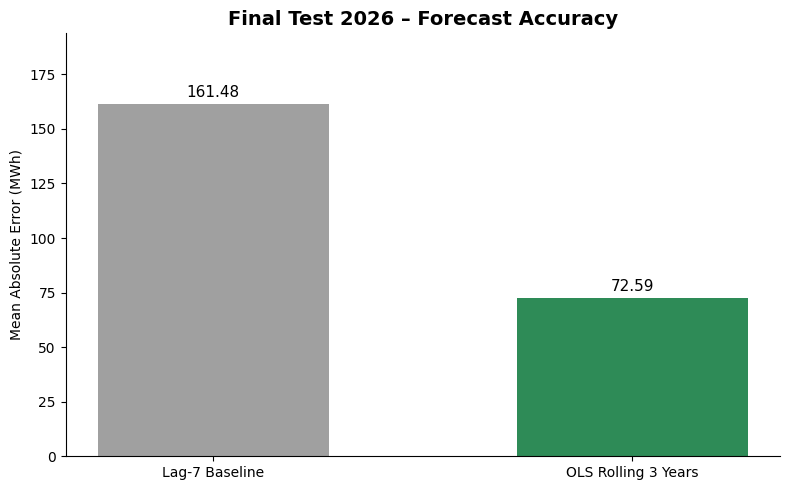

In [11]:

# Visualize final test performance

fig, ax = plt.subplots(figsize=(8, 5))

models = results["Model"]
mae_values = results["MAE (MWh)"]

bars = ax.bar(
    models,
    mae_values,
    color=["#A0A0A0", "#2E8B57"],
    width=0.55
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{bar.get_height():.2f}",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Final Test 2026 – Forecast Accuracy",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Mean Absolute Error (MWh)")
ax.set_ylim(0, max(mae_values) * 1.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()



## 9. Export of Final Test Results

The final test predictions, performance metrics, and model comparison figure are saved to the project's output directory.

The exported files include daily predictions for all 304 test days, a summary of the forecasting errors for both models, and a visualization of their predictive performance.

These outputs provide a reproducible record of the final evaluation and can be used in the project report.


In [12]:

# Create output directories
figures_dir = ROOT / "output" / "figures"
tables_dir = ROOT / "output" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Save daily test predictions
test_predictions.to_csv(
    tables_dir / "final_test_predictions_2026.csv",
    index=False
)

# Save model comparison
results.to_csv(
    tables_dir / "final_test_metrics_2026.csv",
    index=False
)

# Save the figure created in the previous cell
fig.savefig(
    figures_dir / "final_test_model_comparison_2026.png",
    dpi=300,
    bbox_inches="tight"
)

print("All final test results saved successfully.")
print("Predictions: final_test_predictions_2026.csv")
print("Metrics: final_test_metrics_2026.csv")
print("Figure: final_test_model_comparison_2026.png")


All final test results saved successfully.
Predictions: final_test_predictions_2026.csv
Metrics: final_test_metrics_2026.csv
Figure: final_test_model_comparison_2026.png



## 10. Final Test Results and Interpretation

The final model, OLS with weather features and a three-year rolling training window, was selected exclusively based on its performance during the 2025 validation period.

The model was subsequently evaluated on 304 previously unseen test days from January to October 2026, using monthly walk-forward refitting and a five-day information lag.

The model achieved a **MAE of 72.59 MWh** and a **RMSE of 94.63 MWh**. Compared with the Lag-7 baseline (MAE: 161.48 MWh; RMSE: 226.87 MWh), the selected model reduced the mean absolute forecasting error by **55.05%**.

The mean signed error was +8.42 MWh, indicating a slight average underprediction of electricity consumption.

The test performance was similar to the 2025 validation results (MAE: 74.64 MWh; RMSE: 97.66 MWh), suggesting that the selected model generalizes reasonably well to the subsequent test period.

However, the comparison covers different calendar periods, and the evaluation relies on the project's assumptions regarding historical data availability and weather forecasts. The results should therefore be interpreted as a retrospective forecasting evaluation rather than verified real-time operational performance.

Overall, the findings indicate that the selected OLS model substantially outperforms the simple Lag-7 baseline on the 2026 holdout period, without requiring additional model selection or hyperparameter tuning.
